# CT4101 - Final portfolio
This notebook predicts positive cervical biopsy results from patient demographics, behaviours and medical history. It compares a majority-class baseline with logistic regression, KNN and Random Forest using stratified 5-fold cross-validation on the training data. The test set is only used once, at the end, after all models are locked.

# 1. Loading the data

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# load the dataset
df = pd.read_csv(
    "../data/risk_factors_cervical_cancer.csv",
    na_values=["?"]
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (858, 36)


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs: Time since first diagnosis,STDs: Time since last diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
0,18,4.0,15.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
1,15,1.0,14.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
2,34,1.0,NaN,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0
3,52,5.0,16.0,4.0,1.0,37.0,37.0,1.0,3.0,0.0,...,NaN,NaN,1,0,1,0,0,0,0,0
4,46,3.0,21.0,4.0,0.0,0.0,0.0,1.0,15.0,0.0,...,NaN,NaN,0,0,0,0,0,0,0,0


# 2. Data audit
## 2.1 Data types and missing values
I am going to examine the dataset for missing values and variables before determining which is the best pre-processing method for this dataset.

In [24]:
# check data types
print("Data types:")
print(df.dtypes.value_counts())

# count missing values per column
missing_values = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

# display columns containing missing values
display(
    missing_values[missing_values["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)

Data types:
float64    26
int64      10
Name: count, dtype: int64


,Missing Count,Missing Percentage
STDs: Time since first diagnosis,787,91.72
STDs: Time since last diagnosis,787,91.72
IUD (years),117,13.64
IUD,117,13.64
Hormonal Contraceptives,108,12.59
Hormonal Contraceptives (years),108,12.59
STDs (number),105,12.24
STDs,105,12.24
STDs:vulvo-perineal condylomatosis,105,12.24
STDs:vaginal condylomatosis,105,12.24


## 2.2 Duplicates and target distribution
I'm going to check for duplicate rows and see how many patients have positive or negative biopsy results


In [25]:
# check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# check number of positive/negative biopsy results
print("\nBiopsy result counts:")
print(df["Biopsy"].value_counts())

# percentage of each biopsy result
print("\nBiopsy result percentages:")
print((df["Biopsy"].value_counts(normalize=True) * 100).round(2))

# double-check for missing values in the target variable
print("\nMissing values in Biopsy column:")
print("Columns with missing values:", df.isna().any().sum())



Duplicate rows: 23

Biopsy result counts:
Biopsy
0    803
1     55
Name: count, dtype: int64

Biopsy result percentages:
Biopsy
0    93.59
1     6.41
Name: proportion, dtype: float64

Missing values in Biopsy column:
Columns with missing values: 26


Output: 
There are 23 duplicate rows in the dataset. This is something I need to consider before splitting the data as this could affect the evaluation results. As stated before the biopsy results are quite imbalanced as there are 803 negative biopsy results and there are 55 positive biopsy results. This is important to note as a model could achieve high accuracy by predicting negative for each patient without identifying any positive cases. Which is why I need to put emphasis on recall when doing this assignment. There are also 26 columns with missing values which I will also need to handle during pre processing.

## 2.3 Outliers
I'm gonna take a look at the summary statistics to see if there are any unusual values which may need to be looked into

In [26]:
display(df.describe().T)

# examine numerical features closer
columns_to_examine = [
    "Age", "Number of sexual partners", "First sexual intercourse", "Num of pregnancies", "Smokes (years)"]

display(df[columns_to_examine].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,858.0,26.820513,8.497948,13.0,20.0,25.0,32.0,84.0
Number of sexual partners,832.0,2.527644,1.667760,1.0,2.0,2.0,3.0,28.0
First sexual intercourse,851.0,16.995300,2.803355,10.0,15.0,17.0,18.0,32.0
Num of pregnancies,802.0,2.275561,1.447414,0.0,1.0,2.0,3.0,11.0
Smokes,845.0,0.145562,0.352876,0.0,0.0,0.0,0.0,1.0
Smokes (years),845.0,1.219721,4.089017,0.0,0.0,0.0,0.0,37.0
Smokes (packs/year),845.0,0.453144,2.226610,0.0,0.0,0.0,0.0,37.0
Hormonal Contraceptives,750.0,0.641333,0.479929,0.0,0.0,1.0,1.0,1.0
Hormonal Contraceptives (years),750.0,2.256419,3.764254,0.0,0.0,0.5,3.0,30.0
IUD,741.0,0.112011,0.315593,0.0,0.0,0.0,0.0,1.0


,count,mean,std,min,25%,50%,75%,max
Age,858.0,26.820513,8.497948,13.0,20.0,25.0,32.0,84.0
Number of sexual partners,832.0,2.527644,1.667760,1.0,2.0,2.0,3.0,28.0
First sexual intercourse,851.0,16.995300,2.803355,10.0,15.0,17.0,18.0,32.0
Num of pregnancies,802.0,2.275561,1.447414,0.0,1.0,2.0,3.0,11.0
Smokes (years),845.0,1.219721,4.089017,0.0,0.0,0.0,0.0,37.0


output findings:
There are a few high values in the dataset. For example the maximum number of sexual partners is 28 compared to the median of 2, and the maximum number of pregnancies is 11 compared to a median of 2. I'm not going to remove them now however I will consider their impact during preprocessing and modelling 

In [27]:
# noting which columns have more than half of values missing
missing_values = df.isna().mean() * 100

print("\nColumns with more than 50% missing values:")
print(missing_values[missing_values > 50])

# check columns with one one unique non missing value
print("\nColumns with only one unique non-missing value:")
print(df.columns[df.nunique(dropna=True) == 1].tolist())


Columns with more than 50% missing values:
STDs: Time since first diagnosis    91.724942
STDs: Time since last diagnosis     91.724942
dtype: float64

Columns with only one unique non-missing value:
['STDs:cervical condylomatosis', 'STDs:AIDS']


Final thoughts of my data audit:
The dataset contains 858 records and 36 columns. There are 23 duplicate rows however these may represent different patients with the same information which I haven't removed yet. The target value is imbalanced which will be important when evaluating the baseline model. There are 26 columns with missing values. Two columns are both related to the timing of the STD diagnosis so I will probably exclude them. I also found two std related columns with only one unique recorded value which I will exclude as they dont provide any useful information. 

# 3. Data preprocessing
I'm going to remove columns now with too much data missing, columns with no variation and test results which dont align with my prediction question

In [28]:
# columns to exclude
columns_to_exclude = [
    "STDs: Time since first diagnosis",
    "STDs: Time since last diagnosis",
    "STDs:cervical condylomatosis",
    "STDs:AIDS",
    "Hinselmann",
    "Schiller",
    "Citology"
]

# divide input features and target variable
X = df.drop(columns=columns_to_exclude + ["Biopsy"])
Y = df["Biopsy"]

print("\nInput features shape:", X.shape)
print("Target variable shape:", Y.shape)
print("Missing values in target variable:", Y.isna().sum())


Input features shape: (858, 28)
Target variable shape: (858,)
Missing values in target variable: 0


In [29]:
# train/test split is based on the approach outlined in week 4 of the lectures
# stratification is used as the biopsy results are imbalanced

from sklearn.model_selection import train_test_split

# split data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

print("\nTraining set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\n positive biopsy percentage in training set:")
print(round(Y_train.mean() * 100, 2))

print("\n positive biopsy percentage in testing set:")
print(round(Y_test.mean() * 100, 2))


Training set shape: (686, 28)
Testing set shape: (172, 28)

 positive biopsy percentage in training set:
6.41

 positive biopsy percentage in testing set:
6.4


## 3.1 Preprocessing pipeline
I'm going to use median imputation for numerical features and most frequent imputation for binary features. I'm also going to standardise the numerical features as some have larger ranges than others. KNN and logistic regression will both need this later on. Preprocessing will be fit only with training data to avoid data leakage


In [30]:
# preprocessing approach based on week 3 lecture
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# identify binary and continuous features
binary_cols = [
    col for col in X_train.columns
    if set(X_train[col].dropna().unique()).issubset({0, 1})
]

numeric_cols = [
    col for col in X_train.columns
    if col not in binary_cols
]

print("\nBinary columns:", len(binary_cols))
print ("\nNumeric columns:", len(numeric_cols))

# preprocessing for numerical columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# preprocessing for binary columns
binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent"))
])

#combine both preprocessing 
preprocessor = ColumnTransformer([
    ("binary", binary_pipeline, binary_cols),
    ("numeric", numeric_pipeline, numeric_cols)
])







Binary columns: 18

Numeric columns: 10


In [31]:
# fit preprocessing on training data only 
X_train_preprocessed = preprocessor.fit_transform(X_train)

# apply same preprocessing to test data
X_test_preprocessed = preprocessor.transform(X_test)

print("Training data shape:", X_train_preprocessed.shape)
print("Testing data shape:", X_test_preprocessed.shape)

# check for any missing values 
print("Missing values in training data:", np.isnan(X_train_preprocessed).sum())
print("Missing values in testing data:", np.isnan(X_test_preprocessed).sum())

Training data shape: (686, 28)
Testing data shape: (172, 28)
Missing values in training data: 0
Missing values in testing data: 0


Both training sets and testing sets still contain 28 features and there are no missing values remaining. The imputer and scaler were fitted using the training data only to avoid data leakage

## 3.2 Evaluation approach

For this assignment I will be comparing logistic regression, KNN and Random Forest against the majority class baseline. I'll use stratified 5-fold cross validation on the training data to compare the models. This should give a reliable estimate of performance as there are only a few positive biopsy results.
I will compare accuracy, precision, recall and F1 score with recall being the main metric as I want to see how well the models identify positive biopsy cases. The test set will be kept completely separate from the model tuning so that the final evaluation isn't influenced by the model selection process.

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = { 'accuracy': 'accuracy', 'precision': make_scorer(precision_score, zero_division=0), 'recall': 'recall', 'f1': 'f1' }

print("Stratified 5 fold cross validation is set up")

Stratified 5 fold cross validation is set up


# 4. Baseline model
For my baseline I'm using a majority class classifier. Since most patients in the dataset have a negative biopsy result, this model will predict a negative biopsy result for every patient which will give me something to compare the learned models against. 

In [33]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

# create baseline model using the preprocessing pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

In [34]:
# evaluate baseline model using cross-validation

baseline_cv_results = cross_validate(
    baseline_model,
    X_train,
    Y_train,
    cv=cv,
    scoring=scoring
)

print("\nBaseline Model Cross-Validation Results:")

for metric in scoring: 
    scores = baseline_cv_results[f'test_{metric}']
    print(f"{metric.capitalize()}: {scores.mean():.4f} ± {scores.std():.4f}")


Baseline Model Cross-Validation Results:
Accuracy: 0.9359 ± 0.0029
Precision: 0.0000 ± 0.0000
Recall: 0.0000 ± 0.0000
F1: 0.0000 ± 0.0000


# 5. Model comparison

## 5.1 Logistic regression
Logistic regression is the most basic learned model I'm comparing. I'm going to be using balanced class weights because only 6.41% of patients are positive. I'm also testing four values of C, which controls how strongly the model is regularised. A smaller C means stronger regularisation.

In [35]:
from sklearn.linear_model import LogisticRegression

c_values = [0.01, 0.1, 1, 10]
logistic_cv_results = []

for c in c_values:
    logistic_model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(C=c, class_weight="balanced", max_iter=1000))
    ])

    cv_results = cross_validate(
        logistic_model,
        X_train,
        Y_train,
        cv=cv,
        scoring=scoring
    )

    logistic_cv_results.append({
        "C": c,
        "accuracy": cv_results['test_accuracy'].mean(),
        "precision": cv_results['test_precision'].mean(),
        "recall": cv_results['test_recall'].mean(),
        "f1": cv_results['test_f1'].mean()
    })

logistic_cv_results_df = pd.DataFrame(logistic_cv_results)
print("\nLogistic Regression Cross-Validation Results:")
display(logistic_cv_results_df.round(4))


Logistic Regression Cross-Validation Results:


,C,accuracy,precision,recall,f1
0,0.01,0.7653,0.1329,0.4750,0.2071
1,0.10,0.7799,0.1513,0.5194,0.2338
2,1.00,0.7872,0.1402,0.4500,0.2118
3,10.00,0.7930,0.1450,0.4500,0.2168


### Results
I tried four values of C using the same stratified 5-fold cross validation. C=0.1 gave the highest recall of 51.94% and the highest F1 score of 23.38%, so I will use this setting. Changing C didn't make a big difference, as recall stayed between 45% and 52% for all four values.

## 5.2 K-nearest neighbours (KNN)

KNN is the second model I will be testing as it classifies patients based on the similarity of their features to other patients in the training data. It will use distance to find the nearest neighbours and will predict a class based on their labels. I will need to scale the features so that features with larger values won't dominate. I will start with k=5 and compare with larger values to see which performs the best. 

In [36]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# knn will use the existing preprocessor pipeline from Milestone 2 and add the KNN classifier

knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

print("KNN model pipeline created successfully.")

KNN model pipeline created successfully.


In [37]:
# evaluate knn using the same cross-validation setup as the baseline model
knn_cv_results = cross_validate(
    knn_model,
    X_train,
    Y_train,
    cv=cv,
    scoring=scoring
)

print("\nKNN Model Cross-Validation Results:")

for metric in scoring:
    scores = knn_cv_results[f'test_{metric}']
    print(f"{metric.capitalize()}: {scores.mean():.4f} ± {scores.std():.4f}")


KNN Model Cross-Validation Results:
Accuracy: 0.9344 ± 0.0080
Precision: 0.2000 ± 0.4000
Recall: 0.0222 ± 0.0444
F1: 0.0400 ± 0.0800


### Results
From the results above, I can see that KNN achieved a 93.44% accuracy which is a little bit below the baseline. However, unlike the baseline a small number of positive cases were identified. Its recall and f1 scores are very low though. The large variation in precision suggests its performance is inconsistent between folds. I will need to test different values for K. I will tune the knn hyperparameters below.

In [38]:

k_values = [3, 5, 7, 11]
knn_tuning_results = []

for k in k_values:
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    results = cross_validate(
        model,
        X_train,
        Y_train,
        cv=cv,
        scoring=scoring
    )

    knn_tuning_results.append({
        "k": k,
        "accuracy": results["test_accuracy"].mean(),
        "precision": results["test_precision"].mean(),
        "recall": results["test_recall"].mean(),
        "f1": results["test_f1"].mean()
    })

knn_tuning_df = pd.DataFrame(knn_tuning_results)
print(knn_tuning_df.round(4))


    k  accuracy  precision  recall      f1
0   3    0.9300     0.0667  0.0222  0.0333
1   5    0.9344     0.2000  0.0222  0.0400
2   7    0.9329     0.0667  0.0222  0.0333
3  11    0.9359     0.0000  0.0000  0.0000


### Results
I compared the four values of k using the same stratified 5-fold cross validation. k=5 still produced the highest F1 score but k=11 had the highest accuracy but zero recall. Increasing k didnt improve the models ability to identify positive cases so I will keep k=5 as the current setting and compare this against random forest. 

## 5.3 Random Forest

I am going to be using Random Forest as my next model in order to combine multiple decision trees to make predictions. Each tree will be trained on a different bootstrap sample, with random subsets of features considered when splitting nodes. I am going to start with 100 trees before trying other settings. I want to see if a more complex model performs well on a small, highly imbalanced dataset.

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

print("Random Forest pipeline created")

Random Forest pipeline created


In [40]:
rf_cv_results = cross_validate(
    rf_model,
    X_train,
    Y_train,
    cv=cv,
    scoring=scoring
)

print("Random Forest Model Cross-Validation Results:")

for metric in scoring:
    scores = rf_cv_results[f'test_{metric}']
    print(f"{metric.capitalize()}: {scores.mean():.4f} ± {scores.std():.4f}")

Random Forest Model Cross-Validation Results:
Accuracy: 0.9300 ± 0.0059
Precision: 0.2000 ± 0.2449
Recall: 0.0444 ± 0.0544
F1: 0.0727 ± 0.0891


### Results
The results above show that Random Forest achieves around 93% accuracy. Its recall of 4.44% was higher than KNNs 2.2% and its F1 score of 7.27% was also higher. Despite this it still struggled to identify positive biopsy cases. I want to see if changing the settings improves performance.

## 5.4 Random Forest tuning
I am going to now investigate whether tree count, max depth, and class weighting will affect the models ability to identify positive cases

In [41]:

from itertools import product

rf_tuning_results = []

for n_trees, depth, weight in product(
    [100, 200],
    [None, 5],
    [None, "balanced"]
):
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=n_trees,
            max_depth=depth,
            class_weight=weight,
            random_state=42
        ))
    ])

    results = cross_validate(
        model,
        X_train,
        Y_train,
        cv=cv,
        scoring=scoring
    )

    rf_tuning_results.append({
        "n_estimators": n_trees,
        "max_depth": depth,
        "class_weight": weight,
        "accuracy": results["test_accuracy"].mean(),
        "precision": results["test_precision"].mean(),
        "recall": results["test_recall"].mean(),
        "f1": results["test_f1"].mean()
    })

rf_tuning_df = pd.DataFrame(rf_tuning_results)
print(rf_tuning_df.round(4).to_string(index=False))


 n_estimators  max_depth class_weight  accuracy  precision  recall     f1
          100        NaN          NaN    0.9300     0.2000  0.0444 0.0727
          100        NaN     balanced    0.9110     0.2472  0.1361 0.1671
          100        5.0          NaN    0.9359     0.0000  0.0000 0.0000
          100        5.0     balanced    0.8805     0.2312  0.3167 0.2613
          200        NaN          NaN    0.9300     0.1000  0.0222 0.0364
          200        NaN     balanced    0.9066     0.2422  0.1583 0.1838
          200        5.0          NaN    0.9344     0.0000  0.0000 0.0000
          200        5.0     balanced    0.8834     0.2312  0.3389 0.2713


### Results
I tested 8 different Random Forest variations by modifying the number of trees, maximum depth and the class weighting. The results showed that using balanced class weights did overall improve performance particularly when max depth was set to 5. The best performing variation was 200 trees with max depth of 5 and balanced class weights which lead to a recall of 33.89% and an F1 score of 27.13%. Although this combination did have a slightly lower accuracy of 88.34% compared to the original Random Forest run, it was far better at identifying positive cases. However the recall is still low so the model is still missing a large number of positive cases. This shows that class imbalance is an issue for this dataset and higher accuracy doesnt mean better performance. 

## 5.5 Model comparison
I am now going to compare the majority class baseline, logistic regression, KNN and the tuned Random Forest model using the same 5 fold stratified cross validation method.

In [42]:
rf_best_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        class_weight="balanced",
        random_state=42
    ))
])

lr_best_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=0.1, class_weight="balanced", max_iter=1000))
])

models = {
    "Majority Baseline": baseline_model,
    "Logistic Regression (C=0.1)": lr_best_model,
    "KNN (k=5)": knn_model,
    "Random Forest (tuned)": rf_best_model
}

comparison_results = []

for name, model in models.items():
    results = cross_validate(
        model,
        X_train,
        Y_train,
        cv=cv,
        scoring=scoring
    )

    comparison_results.append({
        "Model": name,
        "Accuracy": results["test_accuracy"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1": results["test_f1"].mean(),
        "Recall SD": results["test_recall"].std(),
        "F1 SD": results["test_f1"].std()
    })

comparison_df = pd.DataFrame(comparison_results)

print("Model Comparison Results:")
print(comparison_df.round(4).to_string(index=False))


Model Comparison Results:
                      Model  Accuracy  Precision  Recall     F1  Recall SD  F1 SD
          Majority Baseline    0.9359     0.0000  0.0000 0.0000     0.0000 0.0000
Logistic Regression (C=0.1)    0.7799     0.1513  0.5194 0.2338     0.1008 0.0478
                  KNN (k=5)    0.9344     0.2000  0.0222 0.0400     0.0444 0.0800
      Random Forest (tuned)    0.8834     0.2312  0.3389 0.2713     0.0936 0.0644


### Results
Logistic regression had the highest recall at 51.94%, while the tuned Random Forest had the highest precision and F1 score at 23.12% and 27.13%. Although the baseline achieved the highest accuracy, it didn't identify any positive cases. KNN identified very few positive cases. Since logistic regression and Random Forest each do better on a different metric, I'm going to take both forward and look at their decision thresholds before choosing a final model.

## 5.6 Confusion matrix and error analysis

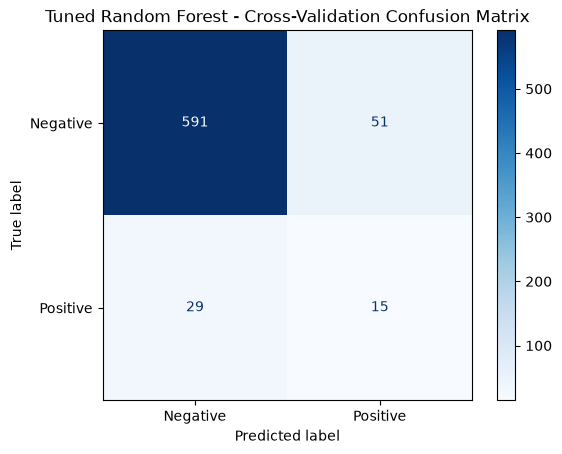

In [43]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

rf_cv_predictions = cross_val_predict(
    rf_best_model,
    X_train,
    Y_train,
    cv=cv
)

cm = confusion_matrix(Y_train, rf_cv_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(cmap="Blues", values_format="d")

plt.title("Tuned Random Forest - Cross-Validation Confusion Matrix")
plt.show()


### Error analysis
The confusion matrix above shows that the tuned Random Forest variation identified 591 negative cases and a total of 15 positive cases. It did however incorrectly predict 51 cases as positive and missed 29 actual positive cases. Although the performance of this model for identifying positive cases was better than both the baseline and KNN, it still missed the majority of them. This is a massive limitation considering that identifying positive biopsy results is the whole aim of the project. The model additionally produces a large number of false positives which shows the trade off in improving recall. Overall there is still room for improvement. 

## 5.7 Duplicate Check
In the data audit previously, I found 23 duplicate rows. I kept them originally as they there are no patient IDs so I wasnt sure if they were the same patient or different patients with the same answer. However if two of the same rows end up in different folds, the model could be tested against a row that it has already seen. This would end up making cross-validation results better then it seems. To try and combate this I'm going to remove the duplicates from the training set and run the same model comparison once again. 

In [44]:
train_data = pd.concat([X_train, Y_train], axis=1)
duplicate_rows = train_data.duplicated()
print("Duplicate rows in training data:", duplicate_rows.sum())

X_train_no_dup = X_train[~duplicate_rows]
Y_train_no_dup = Y_train[~duplicate_rows]
print("Training data without duplicates:", X_train_no_dup.shape)
print("Positive cases removed:", Y_train[duplicate_rows].sum())

dup_results = []

for name, model in models.items():
    results = cross_validate(
        model,
        X_train_no_dup,
        Y_train_no_dup,
        cv=cv,
        scoring=scoring
    )

    dup_results.append({
        "Model": name,
        "Accuracy": results["test_accuracy"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1": results["test_f1"].mean()
    })

dup_df = pd.DataFrame(dup_results)
print("\nModel Comparison Without Duplicates:")
print(dup_df.round(4).to_string(index=False))

Duplicate rows in training data: 14
Training data without duplicates: (672, 28)
Positive cases removed: 0

Model Comparison Without Duplicates:
                      Model  Accuracy  Precision  Recall     F1
          Majority Baseline    0.9345     0.0000  0.0000 0.0000
Logistic Regression (C=0.1)    0.7812     0.1504  0.4972 0.2308
                  KNN (k=5)    0.9301     0.0000  0.0000 0.0000
      Random Forest (tuned)    0.8646     0.1922  0.2500 0.2061


### Results
There were 14 duplicate rows in the training data but none of them were positive cases. After removal, logistic regression stayed the almost the same except recall went from 51.94% to 49.72%. Random Forest dropped further with recall goign from 33.89% to 25% and F1 going from 27.13% to 20.61%. KNN didn't find any positive cases this time. Its hard to know if the duplicates were making Random Forest better as removing the rows would change which patients ended up in each row. With only about 9 positive cases per fold, one patient changes recall by about 11%, and the drop for Random Forest is around one standard deviation. However it does show that logistic regression is more stable than Random Forest. I'm going to keep the duplicates in the main pipeline because they could be different patients with the same answers, and I will mention this as a limitation in my final report. 

# 6. Decision Threshold
Up until now each model predicts a positive biopsy when the predicted probability is at least 0.5. This default isn't necessarily the best choice when the positive cases are already so rare. I'm going to compare logisitic regression and Random Forest across all thresholds and then select a threshold for each, using only the training data. 

## 6.1 Precision-recall curves
A precision recall curve will display the trade off between precision and recall at each threshold. Average Precision (AP) summaries the entire curve as a number. The dashed line is the positive rate which is what a model with no skill would get 

Logistic Regression average precision: 0.122
Random Forest average precision: 0.1417
Positive rate (no-skill line): 0.0641


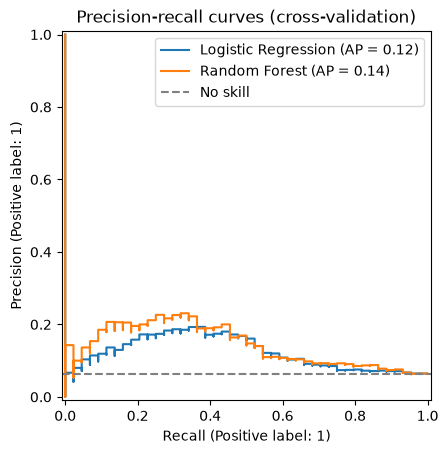

In [45]:
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score

# out of fold predicted probabilities on the training data
lr_probs = cross_val_predict(lr_best_model, X_train, Y_train, cv=cv, method="predict_proba")[:, 1]
rf_probs = cross_val_predict(rf_best_model, X_train, Y_train, cv=cv, method="predict_proba")[:, 1]

print("Logistic Regression average precision:", round(average_precision_score(Y_train, lr_probs), 4))
print("Random Forest average precision:", round(average_precision_score(Y_train, rf_probs), 4))
print("Positive rate (no-skill line):", round(Y_train.mean(), 4))

fig, ax = plt.subplots()
PrecisionRecallDisplay.from_predictions(Y_train, lr_probs, name="Logistic Regression", ax=ax)
PrecisionRecallDisplay.from_predictions(Y_train, rf_probs, name="Random Forest", ax=ax)
ax.axhline(Y_train.mean(), linestyle="--", color="grey", label="No skill")
ax.legend()
plt.title("Precision-recall curves (cross-validation)")
plt.show()

### Results 
Both models are better then non skill as their average precision of 0.122 and 0.1417 is almost double the positive rate of 0.064. But precision never goes above around 0.2 for either model. Random forest does have a higher AP but that comes from low recall. At the recall levesl I actually care about (0.4+) the two curves are extremely close. This implies that the features in this dataset only weakly predict a positive biopsy. 

## 6.2 Choosing a threshold
To choose the threshold I'm going to use the F2 score whicb is just the F1 score with beta set to 2. This will weight recall more then precision which is ideal for this project as missing a positive case is far worse than flagging someone who turns out to be negative.I'll test thresholds from 0.5 to 0.95 and keep the one with the highest F2. 

In [46]:
from sklearn.metrics import recall_score, fbeta_score

thresholds = np.arange(0.05, 1.0, 0.05)
threshold_results = []

for name, probs in [("Logistic Regression", lr_probs), ("Random Forest", rf_probs)]:
    for t in thresholds:
        preds = (probs >= t).astype(int)
        threshold_results.append({
            "Model": name,
            "Threshold": round(t, 2),
            "Precision": precision_score(Y_train, preds, zero_division=0),
            "Recall": recall_score(Y_train, preds),
            "F2": fbeta_score(Y_train, preds, beta=2, zero_division=0)
        })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4).to_string(index=False))

best_thresholds = threshold_df.loc[threshold_df.groupby("Model")["F2"].idxmax()]
print("\nBest threshold for each model:")
print(best_thresholds.round(4).to_string(index=False))

              Model  Threshold  Precision  Recall     F2
Logistic Regression       0.05     0.0641  1.0000 0.2552
Logistic Regression       0.10     0.0642  1.0000 0.2555
Logistic Regression       0.15     0.0630  0.9773 0.2506
Logistic Regression       0.20     0.0633  0.9773 0.2515
Logistic Regression       0.25     0.0638  0.9773 0.2529
Logistic Regression       0.30     0.0666  0.9545 0.2602
Logistic Regression       0.35     0.0733  0.7727 0.2656
Logistic Regression       0.40     0.0973  0.6591 0.3059
Logistic Regression       0.45     0.1168  0.5682 0.3205
Logistic Regression       0.50     0.1503  0.5227 0.3495
Logistic Regression       0.55     0.1739  0.4545 0.3436
Logistic Regression       0.60     0.1910  0.3864 0.3208
Logistic Regression       0.65     0.1781  0.2955 0.2610
Logistic Regression       0.70     0.1296  0.1591 0.1522
Logistic Regression       0.75     0.1081  0.0909 0.0939
Logistic Regression       0.80     0.0556  0.0227 0.0258
Logistic Regression       0.85 

### Results
For logistic regression, best threshold was 0.5 with a recall of 52.27% and F2 of 0.3495. Random forest had a better threshold of 0.4 leading to a raised recall from 34.09% to 54.55%. Anything below around 0.35 the models predict almost all patients as positive which lead to a recall of 100% but precision drops to the positive rate. The recall values are slightly different to the cross-validation table as the predictions are pooled across folds instead of averaged per fold

## 6.3 Final model choice
At their chosen thresholds both models are extremely close. Logistic regression has a slightly higher F2 and Random Forest has a slightly higher average precision. However, I have decided to go with logistic regression with a threshold of 0.5 as my final chosen model as it has a higher F2, was more stable in the duplicate check and it is easier to interpret. Random forest with a threshold of 0.4 will also be run on the test set as a comparison. All models and thresholds will be fixed and won't be edited until after the test set is used. 

# 7. Final evaluation on the test set
All models are now trained on the full training set and ran once on the test set, using the thresholds chosen in section 6. The test set has 172 patients and only 11 positive cases, so each positive case changes recall by about 9%.

In [47]:
from sklearn.metrics import accuracy_score, f1_score

final_models = {
    "Majority Baseline": (baseline_model, 0.5),
    "Logistic Regression (C=0.1)": (lr_best_model, 0.5),
    "KNN (k=5)": (knn_model, 0.5),
    "Random Forest (tuned)": (rf_best_model, 0.4)
}

test_results = []
test_predictions = {}

for name, (model, threshold) in final_models.items():
    model.fit(X_train, Y_train)
    probs = model.predict_proba(X_test)[:, 1]
    preds = (probs >= threshold).astype(int)
    test_predictions[name] = preds

    test_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(Y_test, preds),
        "Precision": precision_score(Y_test, preds, zero_division=0),
        "Recall": recall_score(Y_test, preds),
        "F1": f1_score(Y_test, preds, zero_division=0),
        "F2": fbeta_score(Y_test, preds, beta=2, zero_division=0)
    })

test_df = pd.DataFrame(test_results)
print("Test set results:")
print(test_df.round(4).to_string(index=False))

Test set results:
                      Model  Threshold  Accuracy  Precision  Recall     F1     F2
          Majority Baseline        0.5    0.9360     0.0000  0.0000 0.0000 0.0000
Logistic Regression (C=0.1)        0.5    0.7849     0.1389  0.4545 0.2128 0.3125
                  KNN (k=5)        0.5    0.9360     0.0000  0.0000 0.0000 0.0000
      Random Forest (tuned)        0.4    0.7384     0.1136  0.4545 0.1818 0.2841


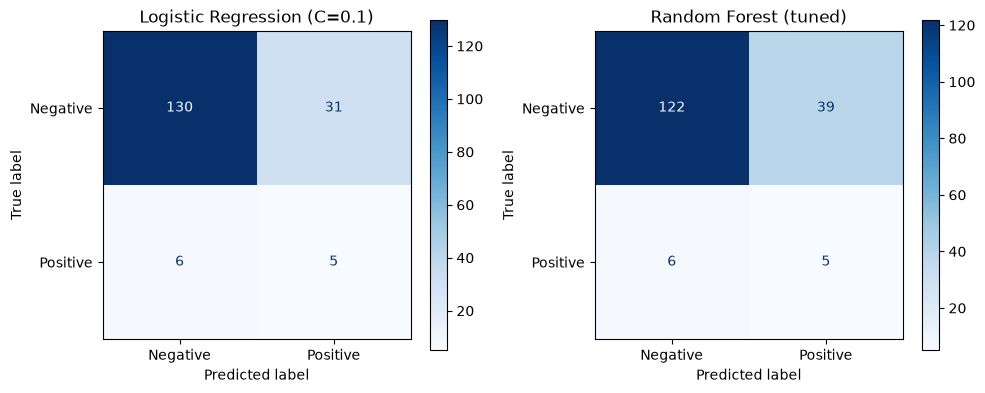

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, name in zip(axes, ["Logistic Regression (C=0.1)", "Random Forest (tuned)"]):
    ConfusionMatrixDisplay.from_predictions(
        Y_test,
        test_predictions[name],
        display_labels=["Negative", "Positive"],
        cmap="Blues",
        values_format="d",
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Results
Logistic regression and Random forest found 5/11 positive cases which is a recall of about 45.45%. This is slightly lower then in cross-validation but with only 11 cases, the one missed patient makes a 9% difference. Logisitic regression does have fewer false positives, so its accuracy, precision and F2 were all higher which was good as it justifies my reasoning for chosing it as the final model. However it still missed 6 positive cases and flags 31 patients who were negative. 